# 03 · Model Evaluation — Hybrid PII Detector

This notebook presents the evaluation results of the **hybrid PII detector** (regex + NumPy token classifier) used in the datathon prototype.

The detector combines strict regex rules for structured Mexican identifiers (CURP, RFC, EMAIL) with a lightweight multinomial logistic-regression token classifier trained on hashed character features. On the Spain AI4Privacy benchmark the operating threshold is set to **0.85** (i.e., a token is flagged as PII whenever the model's P(not-PII) < 0.85). This threshold was chosen to maximise recall — a missed PII value is more costly than over-redacting a neutral word. At this operating point the hybrid detector redacts **98.5 %** of annotated PII characters on the Spain set (6,987 documents) and **99.8 %** on the synthetic Mexican set (400 documents, labels: CURP, RFC, NAME, EMAIL, PHONE, ADDRESS, ID_NUMBER, DATE_TIME).

All numbers below are read directly from `reports/` JSON files; no model inference is run in this notebook.

In [1]:
import json
from pathlib import Path

REPORTS = Path('../reports')

with open(REPORTS / 'metrics_validation.json') as f:
    m_regex = json.load(f)

with open(REPORTS / 'metrics_validation_hybrid.json') as f:
    m_hybrid = json.load(f)

with open(REPORTS / 'metrics_mx.json') as f:
    m_mx = json.load(f)

with open(REPORTS / 'threshold_sweep.json') as f:
    sweep = json.load(f)

print('Reports loaded OK')

Reports loaded OK


## 1 · Character coverage and document leak rate

In [2]:
rows = [
    ('Regex baseline',    'Spain (6,987)',
     f"{m_regex['char_coverage_all_pii']*100:.1f} %",
     f"{m_regex['leak_rate']*100:.1f} %"),
    ('Hybrid (thr=0.85)', 'Spain (6,987)',
     f"{m_hybrid['char_coverage_all_pii']*100:.1f} %",
     f"{m_hybrid['leak_rate']*100:.1f} %"),
    ('Hybrid (thr=0.85)', 'Mexico synth (400)',
     f"{m_mx['char_coverage_all_pii']['after']*100:.1f} %",
     f"{m_mx['leak_rate']['after']*100:.1f} %"),
]

col_w = [22, 20, 20, 22]
header = ('Detector', 'Dataset', 'Char coverage', 'Docs with any leak')
sep = '+' + '+'.join('-' * (w + 2) for w in col_w) + '+'

def row_str(cells):
    return '| ' + ' | '.join(str(c).ljust(w) for c, w in zip(cells, col_w)) + ' |'

print(sep)
print(row_str(header))
print(sep)
for r in rows:
    print(row_str(r))
print(sep)

+------------------------+----------------------+----------------------+------------------------+
| Detector               | Dataset              | Char coverage        | Docs with any leak     |
+------------------------+----------------------+----------------------+------------------------+
| Regex baseline         | Spain (6,987)        | 27.0 %               | 98.2 %                 |
| Hybrid (thr=0.85)      | Spain (6,987)        | 98.5 %               | 18.7 %                 |
| Hybrid (thr=0.85)      | Mexico synth (400)   | 99.8 %               | 2.5 %                  |
+------------------------+----------------------+----------------------+------------------------+


## 2 · Per-type overlap F1 — hybrid detector on Spain benchmark

In [3]:
types_of_interest = ['NAME', 'ADDRESS', 'ID_NUMBER', 'DATE_TIME',
                     'USERNAME', 'EMAIL', 'PHONE', 'PASSWORD', 'IP', 'DEMOGRAPHIC']

col_w2 = [14, 8, 10, 8, 8, 6]
header2 = ('Type', 'Gold', 'Predicted', 'Prec', 'Recall', 'F1')
sep2 = '+' + '+'.join('-' * (w + 2) for w in col_w2) + '+'

def row2(cells):
    return '| ' + ' | '.join(str(c).ljust(w) for c, w in zip(cells, col_w2)) + ' |'

print('Overlap F1  (threshold 0.85, Spain set)')
print(sep2)
print(row2(header2))
print(sep2)
for t in types_of_interest:
    pt = m_hybrid['per_type'].get(t)
    if pt is None:
        continue
    ov = pt['overlap']
    print(row2([t, pt['gold'], pt['predicted'],
                f"{ov['precision']:.3f}",
                f"{ov['recall']:.3f}",
                f"{ov['f1']:.3f}"]))
print(sep2)

Overlap F1  (threshold 0.85, Spain set)
+----------------+----------+------------+----------+----------+--------+
| Type           | Gold     | Predicted  | Prec     | Recall   | F1     |
+----------------+----------+------------+----------+----------+--------+
| NAME           | 5358     | 5985       | 0.747    | 0.942    | 0.833  |
| ADDRESS        | 12231    | 14443      | 0.811    | 0.964    | 0.881  |
| ID_NUMBER      | 10407    | 11211      | 0.917    | 0.973    | 0.944  |
| DATE_TIME      | 8162     | 9160       | 0.881    | 0.989    | 0.932  |
| USERNAME       | 2731     | 3064       | 0.823    | 0.914    | 0.866  |
| EMAIL          | 2536     | 2566       | 0.970    | 0.982    | 0.976  |
| PHONE          | 2007     | 2869       | 0.766    | 0.988    | 0.863  |
| PASSWORD       | 1634     | 2935       | 0.605    | 0.979    | 0.748  |
| IP             | 2217     | 3283       | 0.690    | 1.000    | 0.817  |
| DEMOGRAPHIC    | 3904     | 4188       | 0.917    | 0.986    | 0.951  

## 3 · Threshold sweep — Spain and Mexico

In [4]:
col_w3 = [10, 8, 14, 16, 16]
header3 = ('Threshold', 'Set', 'Leak rate', 'Char coverage', 'Micro precision')
sep3 = '+' + '+'.join('-' * (w + 2) for w in col_w3) + '+'

def row3(cells):
    return '| ' + ' | '.join(str(c).ljust(w) for c, w in zip(cells, col_w3)) + ' |'

print(sep3)
print(row3(header3))
print(sep3)
for entry in sweep:
    marker = '  ← chosen' if entry['threshold'] == 0.85 else ''
    print(row3([
        str(entry['threshold']) + marker,
        entry['set'],
        f"{entry['leak_rate']*100:.1f} %",
        f"{entry['char_coverage']*100:.2f} %",
        f"{entry['micro_precision']:.4f}",
    ]))
print(sep3)

+------------+----------+----------------+------------------+------------------+
| Threshold  | Set      | Leak rate      | Char coverage    | Micro precision  |
+------------+----------+----------------+------------------+------------------+
| 0.5        | spain    | 37.9 %         | 96.29 %          | 0.8932           |
| 0.5        | mx       | 7.2 %          | 99.72 %          | 0.7997           |
| 0.7        | spain    | 26.5 %         | 97.71 %          | 0.8696           |
| 0.7        | mx       | 3.8 %          | 99.78 %          | 0.7862           |
| 0.85  ← chosen | spain    | 18.7 %         | 98.51 %          | 0.8308           |
| 0.85  ← chosen | mx       | 2.5 %          | 99.79 %          | 0.6982           |
| 0.95       | spain    | 12.4 %         | 98.99 %          | 0.7324           |
| 0.95       | mx       | 3.0 %          | 99.75 %          | 0.5913           |
+------------+----------+----------------+------------------+------------------+


## 4 · Charts

--- Hero chart: coverage & leak rate ---


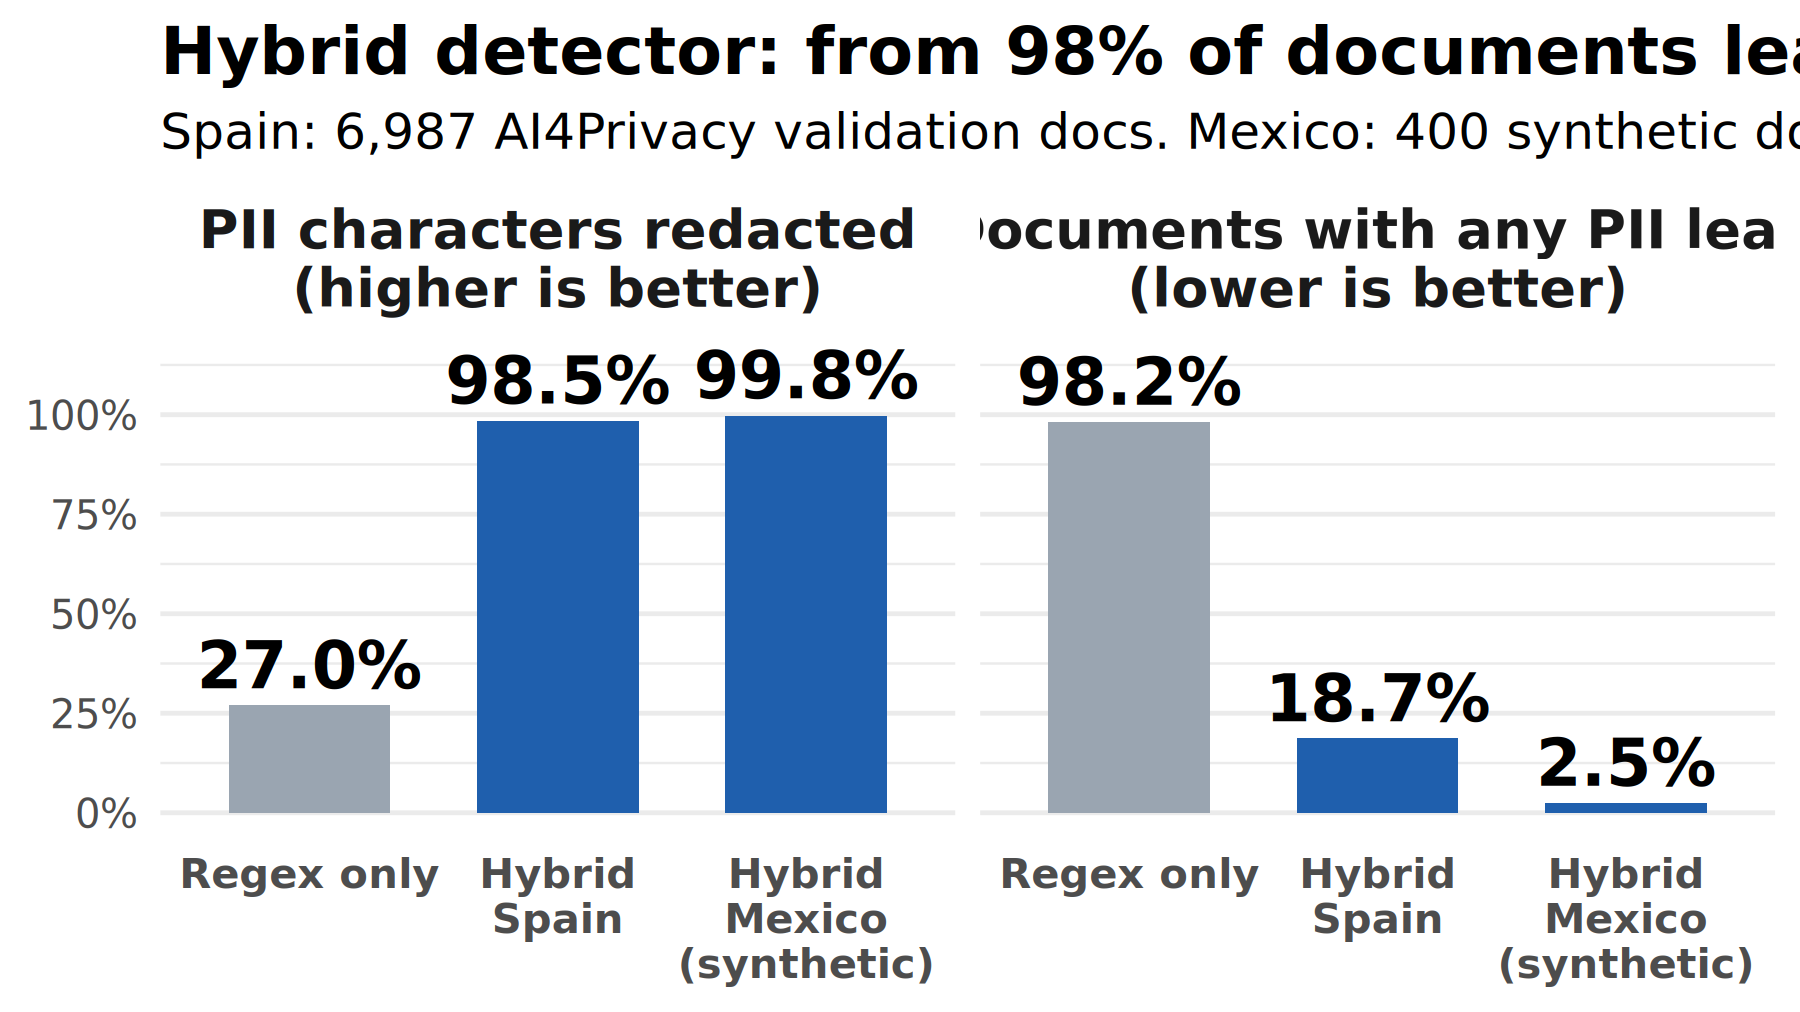

In [5]:
from IPython.display import Image, display
FIGS = Path('../reports/figures')

print('--- Hero chart: coverage & leak rate ---')
display(Image(filename=str(FIGS / '06_hero.png')))

--- Mexico: before vs after MX rules ---


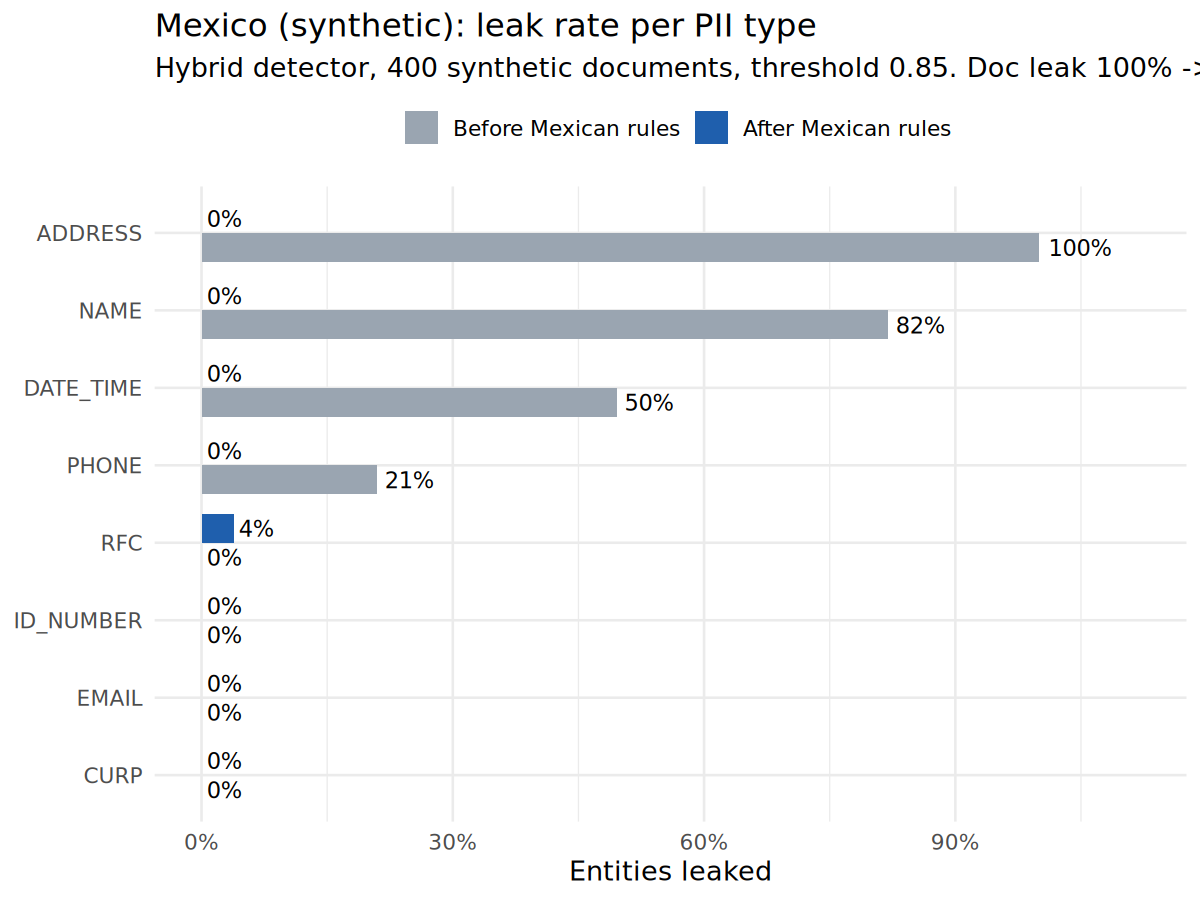

In [6]:
print('--- Mexico: before vs after MX rules ---')
display(Image(filename=str(FIGS / '07_mx_before_after.png')))

--- Threshold sweep ---


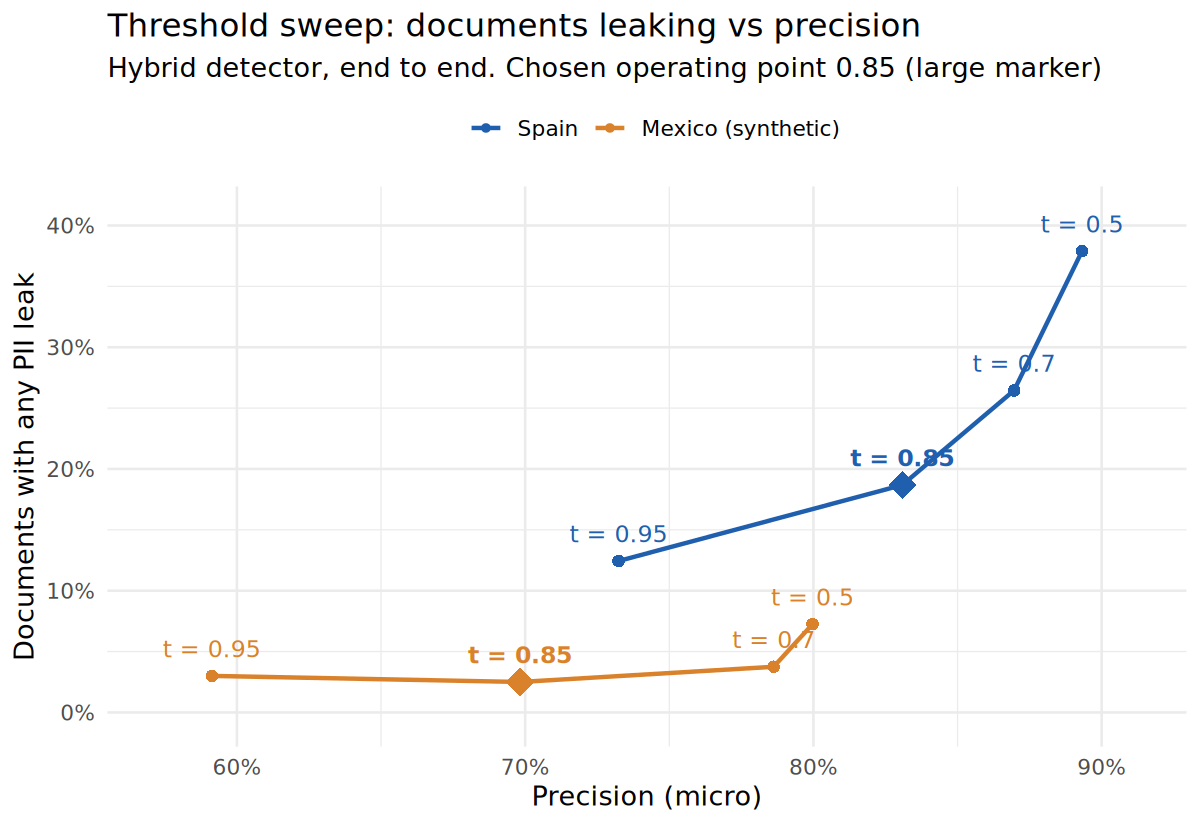

In [7]:
print('--- Threshold sweep ---')
display(Image(filename=str(FIGS / '08_threshold_sweep.png')))